#Project 11: Handwritten Digit Classification Using CNN

Description:

Students will build a basic CNN model to classify handwritten digits using the MNIST dataset. The project introduces image preprocessing, convolutional layers, pooling layers, and classification.

Task 1: Load and preprocess the MNIST handwritten digit dataset.

Task 2: Build and train a basic CNN model.

Task 3: Evaluate the model using accuracy, a confusion matrix, classification report, and sample predictions.

Expected Output/Result:

Students will obtain a trained CNN model for handwritten digit classification. The confusion matrix will help identify which digits are frequently misclassified, while the classification report will show precision, recall, and F1-score for each class.

## 1. Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 2. Load and preprocess MNIST

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image dimensions:", train_dataset[0][0].shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 503kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.47MB/s]

Training images: 60000
Testing images: 10000
Image dimensions: torch.Size([1, 28, 28])


## 3. Display sample images

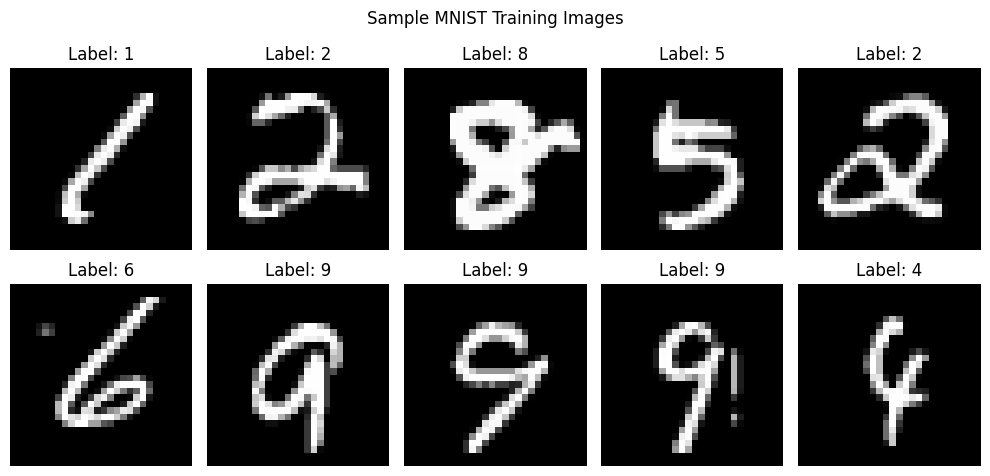

In [3]:
def denormalize(image):
    return image * 0.3081 + 0.1307

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(denormalize(images[i]).squeeze(), cmap="gray")
    ax.set_title("Label: {}".format(labels[i].item()))
    ax.axis("off")
plt.suptitle("Sample MNIST Training Images")
plt.tight_layout()
plt.show()

## 4. Define the CNN model

In [4]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = DigitCNN().to(device)
print(model)

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 5. Train the CNN

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 5
train_losses = []
train_accuracies = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad()
        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_images.size(0)
        correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
        total += batch_labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    print("Epoch {}/{} - Loss: {:.4f} - Training Accuracy: {:.2f}%".format(
        epoch + 1, EPOCHS, epoch_loss, epoch_accuracy * 100
    ))

Epoch 1/5 - Loss: 0.1639 - Training Accuracy: 94.98%
Epoch 2/5 - Loss: 0.0553 - Training Accuracy: 98.31%
Epoch 3/5 - Loss: 0.0405 - Training Accuracy: 98.71%
Epoch 4/5 - Loss: 0.0306 - Training Accuracy: 99.02%
Epoch 5/5 - Loss: 0.0252 - Training Accuracy: 99.19%


## 6. Plot training loss and accuracy

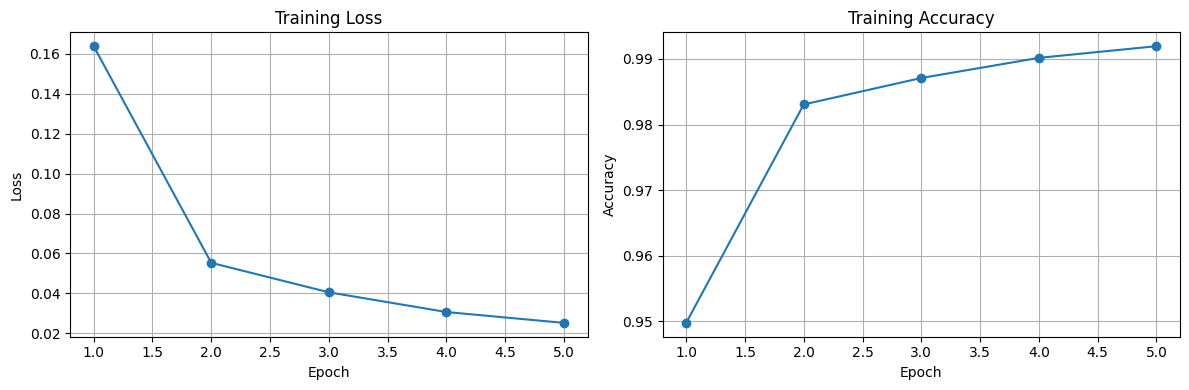

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, EPOCHS + 1), train_losses, marker="o")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(range(1, EPOCHS + 1), train_accuracies, marker="o")
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)
plt.tight_layout()
plt.show()

## 7. Evaluate on the test dataset

In [7]:
model.eval()
all_predictions = []
all_labels = []
all_images = []

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        outputs = model(batch_images.to(device))
        predictions = outputs.argmax(dim=1)
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch_labels.numpy())
        all_images.extend(batch_images.cpu())

test_accuracy = accuracy_score(all_labels, all_predictions)
print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))

Test Accuracy: 99.25%


## 8. Confusion matrix

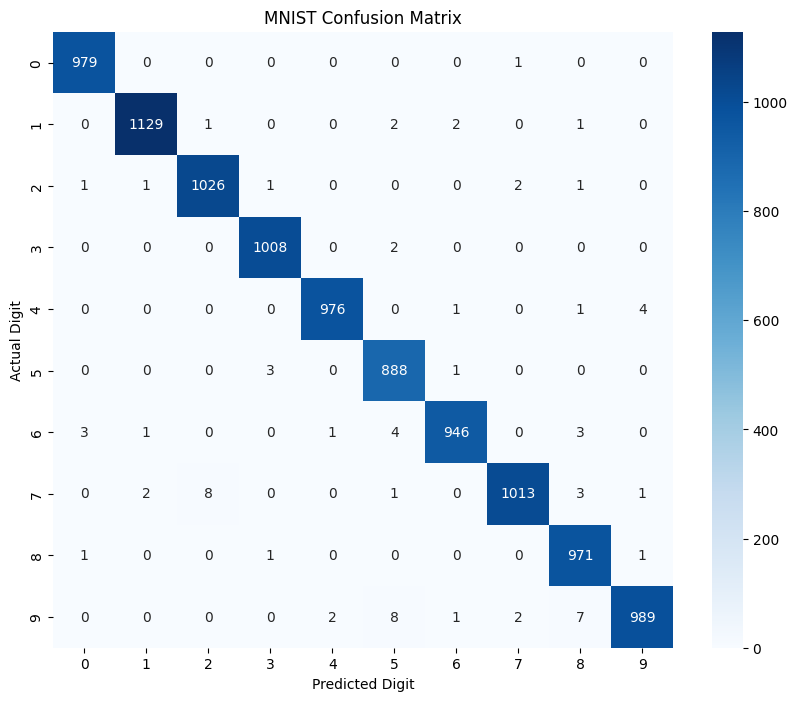

In [8]:
cm = confusion_matrix(all_labels, all_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("MNIST Confusion Matrix")
plt.show()

## 9. Classification report

In [9]:
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(10)),
    target_names=[str(i) for i in range(10)],
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

           0     0.9949    0.9990    0.9969       980
           1     0.9965    0.9947    0.9956      1135
           2     0.9913    0.9942    0.9927      1032
           3     0.9951    0.9980    0.9965      1010
           4     0.9969    0.9939    0.9954       982
           5     0.9812    0.9955    0.9883       892
           6     0.9947    0.9875    0.9911       958
           7     0.9951    0.9854    0.9902      1028
           8     0.9838    0.9969    0.9903       974
           9     0.9940    0.9802    0.9870      1009

    accuracy                         0.9925     10000
   macro avg     0.9923    0.9925    0.9924     10000
weighted avg     0.9925    0.9925    0.9925     10000



## 10. Display sample predictions

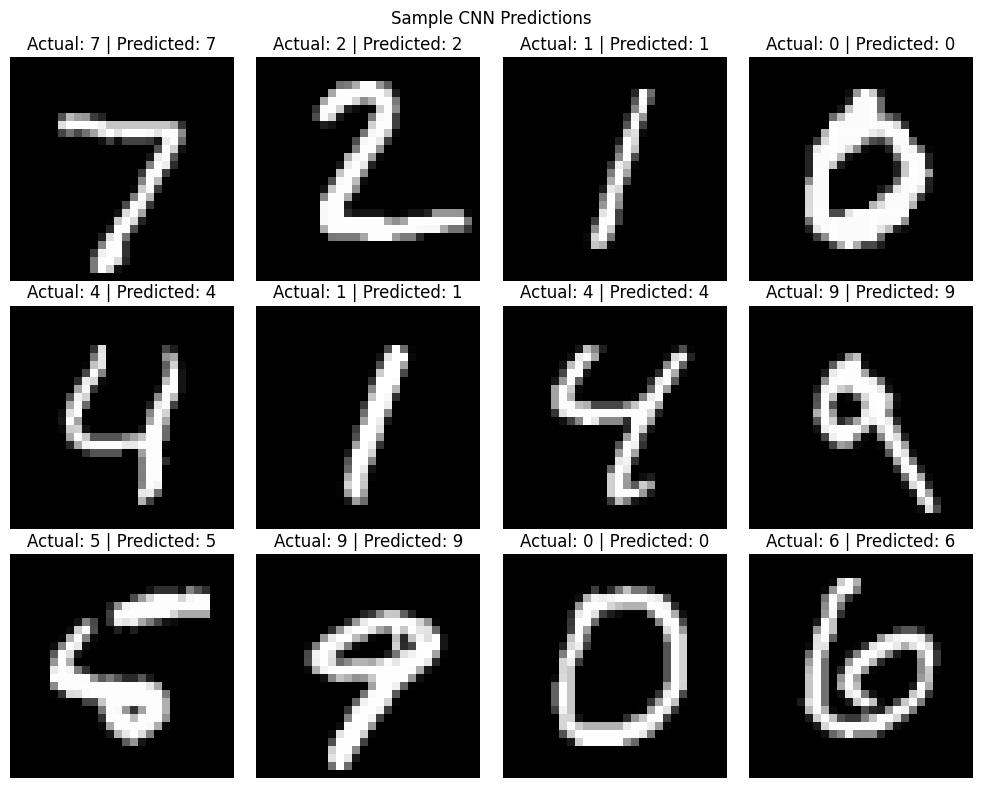

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for i, ax in enumerate(axes.flatten()):
    image = all_images[i]
    actual = all_labels[i]
    predicted = all_predictions[i]
    ax.imshow(denormalize(image).squeeze(), cmap="gray")
    ax.set_title("Actual: {} | Predicted: {}".format(actual, predicted))
    ax.axis("off")
plt.suptitle("Sample CNN Predictions")
plt.tight_layout()
plt.show()

## 11. Display misclassified examples

Number of misclassified test images: 75


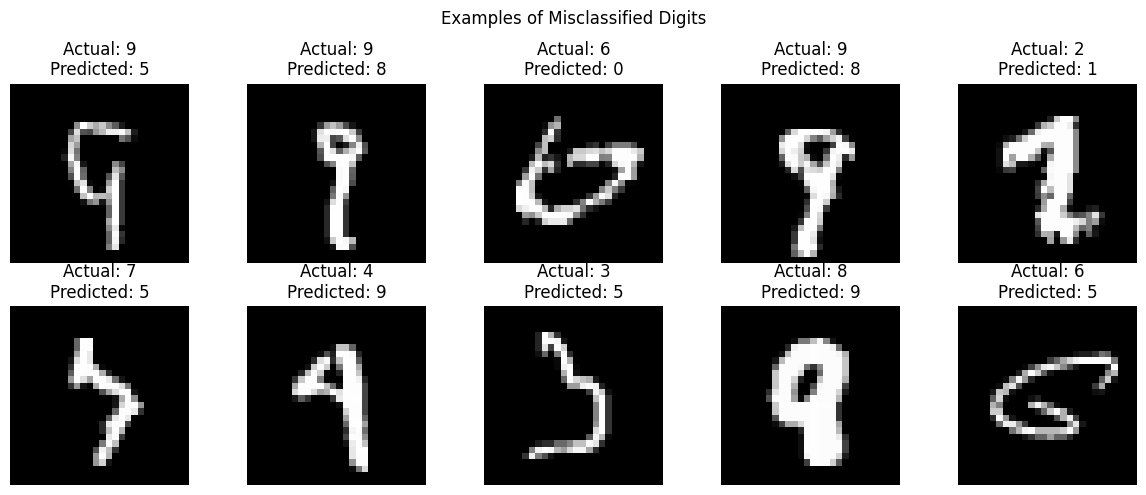

In [11]:
wrong_indices = [
    i for i, (actual, predicted) in enumerate(zip(all_labels, all_predictions))
    if actual != predicted
]
print("Number of misclassified test images:", len(wrong_indices))

if wrong_indices:
    count = min(10, len(wrong_indices))
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax, idx in zip(axes.flatten(), wrong_indices[:count]):
        ax.imshow(denormalize(all_images[idx]).squeeze(), cmap="gray")
        ax.set_title("Actual: {}\nPredicted: {}".format(all_labels[idx], all_predictions[idx]))
        ax.axis("off")
    for ax in axes.flatten()[count:]:
        ax.axis("off")
    plt.suptitle("Examples of Misclassified Digits")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified examples were found.")

## 12. Save the trained model

In [12]:
MODEL_PATH = "SohamSen_DL_Project11_CNN.pth"
torch.save(model.state_dict(), MODEL_PATH)
print("Model weights saved to:", MODEL_PATH)

Model weights saved to: SohamSen_DL_Project11_CNN.pth


## 13. Conclusion

In this project, a Convolutional Neural Network was trained to classify handwritten digits from the MNIST dataset. The images were converted to tensors and normalized. Convolutional and pooling layers learned image features, while fully connected layers performed classification. The model was evaluated using test accuracy, a confusion matrix, a classification report, and sample predictions. The confusion matrix and misclassified examples help identify digits the model confuses. Use the measured accuracy and observed errors to describe the model's actual performance.

